In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/Victory-Data/Superstore-Sales-Dataset/main/Sample%20-%20Superstore.csv"

df = pd.read_csv(url, encoding="latin1")

print(df.dtypes)


Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/Victory-Data/Superstore-Sales-Dataset/main/Sample%20-%20Superstore.csv"

df = pd.read_csv(url, encoding="latin1")

df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df.dtypes)

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [4]:
df["year"] = df["Order Date"].dt.year
df["month"] = df["Order Date"].dt.month
print(df[["Order Date", "year", "month"]].head())

  Order Date  year  month
0 2016-11-08  2016     11
1 2016-11-08  2016     11
2 2016-06-12  2016      6
3 2015-10-11  2015     10
4 2015-10-11  2015     10


In [5]:
yearly_sales = df.groupby("year")["Sales"].sum()
print(yearly_sales)
print("year with highest sale: ",yearly_sales.idxmax())
print("highest sales amount : ",yearly_sales.max())

year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64
year with highest sale:  2017
highest sales amount :  733215.2552


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<function matplotlib.pyplot.show(close=None, block=None)>

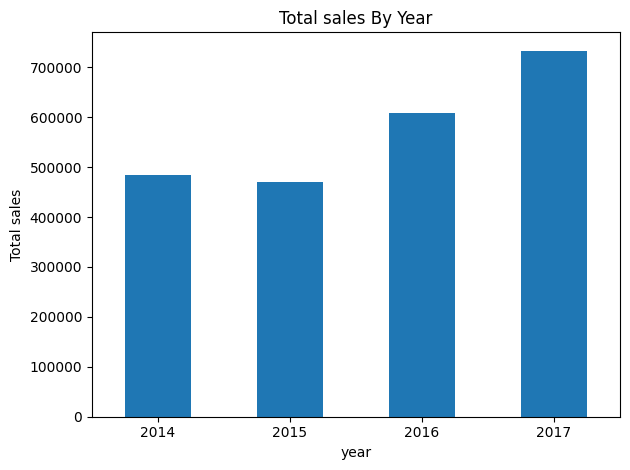

In [6]:
import matplotlib.pyplot as plt
yearly_sales.plot(kind="bar")
plt.title("Total sales By Year")
plt.xlabel("year")
plt.ylabel("Total sales")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show

In [7]:
monthly_sales = df.groupby("month")["Sales"].sum()
print("best month: " , monthly_sales.idxmax())
print("Highest monthly sales:", monthly_sales.max())


best month:  11
Highest monthly sales: 352461.071


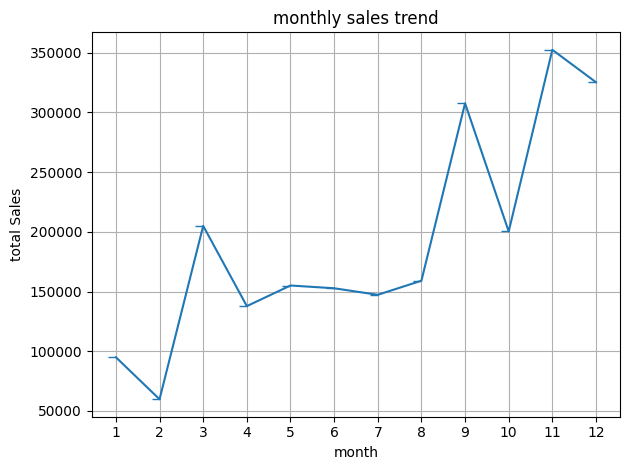

In [8]:
monthly_sales.plot(kind="line",marker=0)
plt.title("monthly sales trend")
plt.xlabel("month")
plt.ylabel("total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
category_analysis = df.groupby("Category")[["Sales","Profit"]].sum()
print(category_analysis)

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


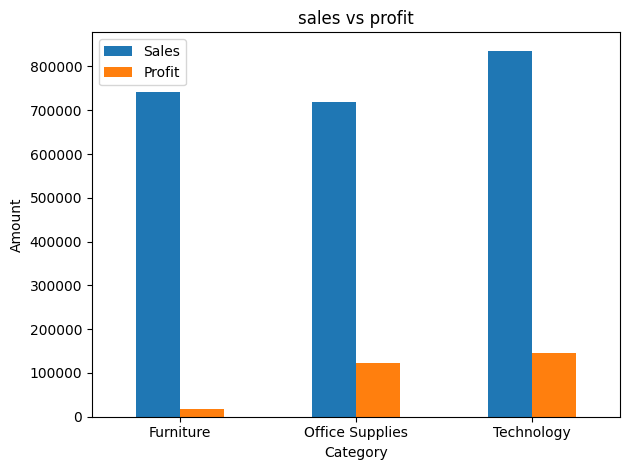

In [10]:
category_analysis.plot(kind="bar")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.title("sales vs profit")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [11]:
product_profit = df.groupby("Product Name")["Profit"].sum()
top_10_products = product_profit.sort_values(ascending=False).head(10)
print(top_10_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


In [12]:
loss_products= product_profit.sort_values().head(10)
print(loss_products)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


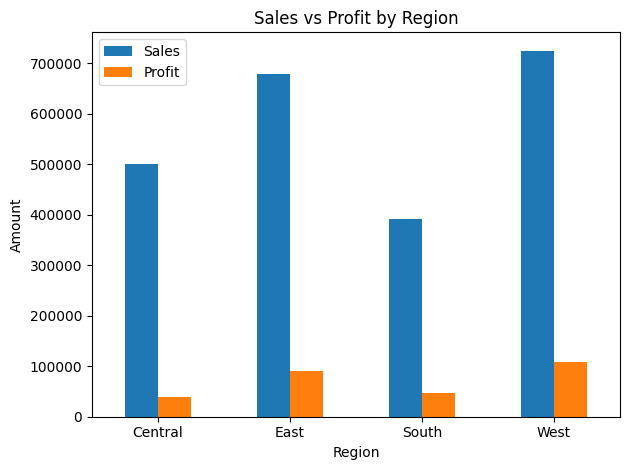

In [13]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_analysis)

region_analysis.plot(kind="bar")
plt.title("Sales vs Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                 Sales      Profit
Discount                          
0.00      1.087908e+06   66.900292
0.10      5.436935e+04   96.055074
0.15      2.755852e+04   27.288298
0.20      7.645944e+05   24.702572
0.30      1.032267e+05  -45.679636
0.32      1.449346e+04  -88.560656
0.40      1.164178e+05 -111.927429
0.45      5.484974e+03 -226.646464
0.50      5.891854e+04 -310.703456
0.60      6.644700e+03  -43.077212
0.70      4.062028e+04  -95.874060
0.80      1.696376e+04 -101.796797


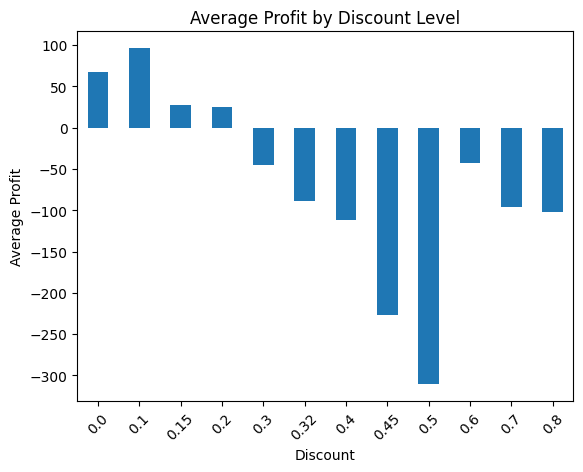

In [14]:
discount_analysis = df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "mean"
})
print(discount_analysis)

discount_analysis["Profit"].plot(kind="bar")
plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.xticks(rotation=45)
plt.tight_layout
plt.show()

In [15]:
print("YEARLY SALES")
print(yearly_sales.round(2).to_string())

print("\nREGIONAL SALES AND PROFIT")
print(region_analysis.round(2).to_string())

print("\nTOP 3 PROFITABLE PRODUCTS")
print(top_10_products.head(3).round(2).to_string())

print("\nTOP 3 LOWEST-PROFIT PRODUCTS")
print(loss_products.head(3).round(2).to_string())

YEARLY SALES
year
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26

REGIONAL SALES AND PROFIT
             Sales     Profit
Region                       
Central  501239.89   39706.36
East     678781.24   91522.78
South    391721.90   46749.43
West     725457.82  108418.45

TOP 3 PROFITABLE PRODUCTS
Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.04
Hewlett Packard LaserJet 3310 Copier                                            6983.88

TOP 3 LOWEST-PROFIT PRODUCTS
Product Name
Cubify CubeX 3D Printer Double Head Print   -8879.97
Lexmark MX611dhe Monochrome Laser Printer   -4589.97
Cubify CubeX 3D Printer Triple Head Print   -3839.99
